# 03 — SES: Suavização Exponencial Simples

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE1 + OE2 — Modelos estatísticos clássicos

---
### O que é o SES
A Suavização Exponencial Simples (SES) produz previsões como média ponderada das observações passadas, onde pesos decaem exponencialmente com a distância temporal. O parâmetro α (0 < α < 1) controla a velocidade desse decaimento:
- **α próximo de 1** → modelo reage rápido, dá muito peso ao último valor
- **α próximo de 0** → modelo é inercial, pondera longo histórico

**Limitação intencional**: SES não modela tendência nem sazonalidade — produz previsão constante (nível atual estimado) para todos os H passos. Por isso serve como referência para séries sem esses padrões e como baseline para comparar com Holt-Winters.

### Posição na dissertação (seção 2.2)
SES é incluído como representante da família de suavização exponencial simples, utilizado em contextos de previsão de curto prazo em séries sem tendência ou sazonalidade identificável.

## 1. Imports e configurações

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

warnings.filterwarnings('ignore')

# ── Caminhos (funciona com cwd em autopred/ ou notebooks/) ───────────────────
import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'paths.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.paths import DATA_DIR, PROJECT_ROOT, RESULT_DIR

RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Verificação antes de rodar o pipeline
_required = {
    'Monthly-train.csv': DATA_DIR / 'Monthly-train.csv',
    'Monthly-test.csv':  DATA_DIR / 'Monthly-test.csv',
}
_missing = [name for name, p in _required.items() if not p.is_file()]
if _missing:
    raise FileNotFoundError(
        f'Arquivos não encontrados em {DATA_DIR}: {_missing}\n'
        f'PROJECT_ROOT = {PROJECT_ROOT}'
    )
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')
print(f'RESULT_DIR     = {RESULT_DIR}')

SEED      = 42
H         = 18
MIN_TRAIN = 24
N_ORIGINS = 3
PILOT_N   = 200

np.random.seed(SEED)
print('Configuração carregada OK')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
DATA_DIR       = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw  OK
RESULT_DIR     = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results
Configuração carregada OK


## 2. Funções base (pipeline padrão)

In [2]:
def load_m4_monthly(data_dir):
    train_raw = pd.read_csv(data_dir / 'Monthly-train.csv')
    test_raw  = pd.read_csv(data_dir / 'Monthly-test.csv')
    def wide_to_long(df):
        id_col = df.columns[0]
        melted = df.melt(id_vars=id_col, value_vars=df.columns[1:],
                         var_name='step_raw', value_name='y')
        melted = melted.rename(columns={id_col: 'unique_id'})
        melted['step'] = melted['step_raw'].str.extract(r'(\d+)').astype(int)
        melted = melted.drop(columns='step_raw').dropna(subset=['y'])
        return melted.sort_values(['unique_id','step']).reset_index(drop=True)
    return wide_to_long(train_raw), wide_to_long(test_raw)

def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]

def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn):
    records = []
    for uid in train_df['unique_id'].unique():
        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)
        if not windows:
            records.append({'unique_id':uid,'model':model_name,'origin':None,
                            'n_train':None,'mape':None,'mae':None,'r2':None,
                            'exec_time_s':None,'status':'SKIP_SHORT'})
            continue
        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {e}'
            records.append({
                'unique_id'  : uid,
                'model'      : model_name,
                'origin'     : win['origin'],
                'n_train'    : len(win['train']),
                **metrics,
                'exec_time_s': time.perf_counter()-t0,
                'status'     : status
            })
    return pd.DataFrame(records)

print('Funções base OK')

Funções base OK


## 3. Carregamento e piloto

In [3]:
train_df, test_df = load_m4_monthly(DATA_DIR)
rng       = np.random.default_rng(SEED)
pilot_ids = rng.choice(train_df['unique_id'].unique(), size=PILOT_N, replace=False)
train_pilot = train_df[train_df['unique_id'].isin(pilot_ids)].copy()
print(f'Piloto: {PILOT_N} séries | {len(train_pilot):,} linhas')

Piloto: 200 séries | 44,224 linhas


## 4. Modelo SES

O parâmetro α é **estimado automaticamente por MLE** (máxima verossimilhança) pelo statsmodels — não fixamos um valor, deixamos o modelo encontrar o melhor α para cada série individualmente. Isso está alinhado com a seção 4.3 da dissertação (seleção por critérios de informação/otimização).

**Por que SES produz previsão constante?**  
SES estima apenas o nível atual da série (sem tendência e sem sazonalidade). Toda previsão futura é igual a esse nível estimado — uma linha horizontal. Isso é adequado para séries estacionárias mas limitado para séries com tendência ou sazonalidade, como a maior parte do M4 mensal.

In [4]:
def model_ses(train, horizon):
    """
    Suavização Exponencial Simples com α otimizado por MLE.
    Produz previsão constante (nível estimado) para todos os H passos.
    Fallback para média histórica se o ajuste falhar.
    """
    try:
        fit = SimpleExpSmoothing(
            train,
            initialization_method='estimated'
        ).fit(optimized=True)
        # forecast retorna H valores iguais ao nível estimado
        return fit.forecast(horizon)
    except Exception:
        # fallback: média histórica
        return np.full(horizon, np.mean(train))


# ── Verificação do comportamento ─────────────────────────────────────────────
ex_estacionaria = np.array([100,98,102,99,101,100,103,97,101,100,
                             99,102,98,101,100,99,102,100,101,98], dtype=float)
ex_tendencia    = np.linspace(100, 150, 20)

pred_est = model_ses(ex_estacionaria, horizon=6)
pred_ten = model_ses(ex_tendencia,    horizon=6)

print('Série estacionária (SES deve funcionar bem):')
print(f'  Previsão: {pred_est.round(2)}')
print(f'  Constante? {np.allclose(pred_est, pred_est[0])}')

print('\nSérie com tendência (SES vai ficar abaixo do real):')
print(f'  Último treino : {ex_tendencia[-1]:.1f}')
print(f'  Previsão SES  : {pred_ten.round(2)}')
print(f'  Constante?    : {np.allclose(pred_ten, pred_ten[0])}')

Série estacionária (SES deve funcionar bem):
  Previsão: [100.05 100.05 100.05 100.05 100.05 100.05]
  Constante? True

Série com tendência (SES vai ficar abaixo do real):
  Último treino : 150.0
  Previsão SES  : [150. 150. 150. 150. 150. 150.]
  Constante?    : True


## 5. Execução do pipeline

In [5]:
print(f'Rodando SES em {PILOT_N} séries...')
t0 = time.time()

results_ses = run_pipeline(
    train_df   = train_pilot,
    horizon    = H,
    min_train  = MIN_TRAIN,
    n_origins  = N_ORIGINS,
    model_name = 'ses',
    predict_fn = model_ses
)

elapsed = time.time() - t0
ok_n    = (results_ses['status'] == 'OK').sum()
err_n   = results_ses['status'].str.startswith('ERROR', na=False).sum()
skip_n  = (results_ses['status'] == 'SKIP_SHORT').sum()

print(f'Concluído em {elapsed:.1f}s')
print(f'  OK           : {ok_n} janelas')
print(f'  Skip (curta) : {skip_n}')
print(f'  Erros        : {err_n}')
print(f'  Taxa sucesso : {100*ok_n/(ok_n+err_n):.1f}%')

Rodando SES em 200 séries...
Concluído em 2.8s
  OK           : 600 janelas
  Skip (curta) : 0
  Erros        : 0
  Taxa sucesso : 100.0%


## 6. Resultados e comparação com modelos anteriores

In [6]:
ok_ses = results_ses[results_ses['status'] == 'OK'].copy()

# Agrega por série
by_series_ses = (
    ok_ses.groupby('unique_id')[['mape','mae','r2','exec_time_s']]
    .median().reset_index()
)

print('=== Desempenho SES ===')
print(by_series_ses[['mape','mae','r2']].describe().round(3).to_string())
print(f'\nMAPE mediano = {by_series_ses["mape"].median():.4f}%')
print(f'MAE  mediano = {by_series_ses["mae"].median():.4f}')
print(f'R²   mediano = {by_series_ses["r2"].median():.4f}')
print(f'Tempo mediano= {by_series_ses["exec_time_s"].median():.4f}s')

=== Desempenho SES ===
          mape       mae       r2
count  200.000   200.000  200.000
mean    12.666   477.568   -1.704
std     14.286   689.191    1.951
min      1.080    17.144  -14.135
25%      3.577   111.398   -2.272
50%      8.776   253.520   -1.190
75%     15.943   552.272   -0.396
max    125.169  6152.222   -0.003

MAPE mediano = 8.7764%
MAE  mediano = 253.5196
R²   mediano = -1.1898
Tempo mediano= 0.0038s


In [7]:
# Carrega resultados anteriores para comparação acumulada
prev_path = RESULT_DIR / 'results_nb02_by_series.csv'

if prev_path.exists():
    prev = pd.read_csv(prev_path)
    # Adiciona SES
    ses_row = by_series_ses.copy()
    ses_row['model'] = 'ses'
    combined = pd.concat([prev, ses_row], ignore_index=True)
else:
    print('Arquivo do notebook 02 não encontrado — mostrando só SES')
    combined = by_series_ses.copy()
    combined['model'] = 'ses'

# Tabela comparativa acumulada
summary = (
    combined.groupby('model')[['mape','mae','r2','exec_time_s']]
    .median().round(4)
    .sort_values('mape')
)

name_map = {
    'holt_winters'   : 'Holt-Winters',
    'ses'            : 'SES',
    'persistence'    : 'Persistência',
    'seasonal_naive' : 'Sazonal ingênuo',
    'mean'           : 'Média histórica',
}
summary.index = [name_map.get(i, i) for i in summary.index]
summary.columns = ['MAPE (%)', 'MAE', 'R²', 'Tempo (s)']

print('=== Comparação acumulada — todos os modelos até agora ===')
print(summary.to_string())

summary.to_csv(RESULT_DIR / 'tabela_acumulada_nb03_ses.csv')
print('\nTabela salva em results/tabela_acumulada_nb03_ses.csv')

=== Comparação acumulada — todos os modelos até agora ===
                 MAPE (%)       MAE      R²  Tempo (s)
Holt-Winters       8.2606  256.0183 -1.0642     0.1852
Persistência       8.6992  274.1667 -1.2684     0.0004
SES                8.7764  253.5196 -1.1898     0.0038
Sazonal ingênuo   11.0601  316.8889 -2.1744     0.0004
Média histórica   18.5971  589.9421 -6.4779     0.0004

Tabela salva em results/tabela_acumulada_nb03_ses.csv


## 7. Visualização — distribuição de α estimado por série

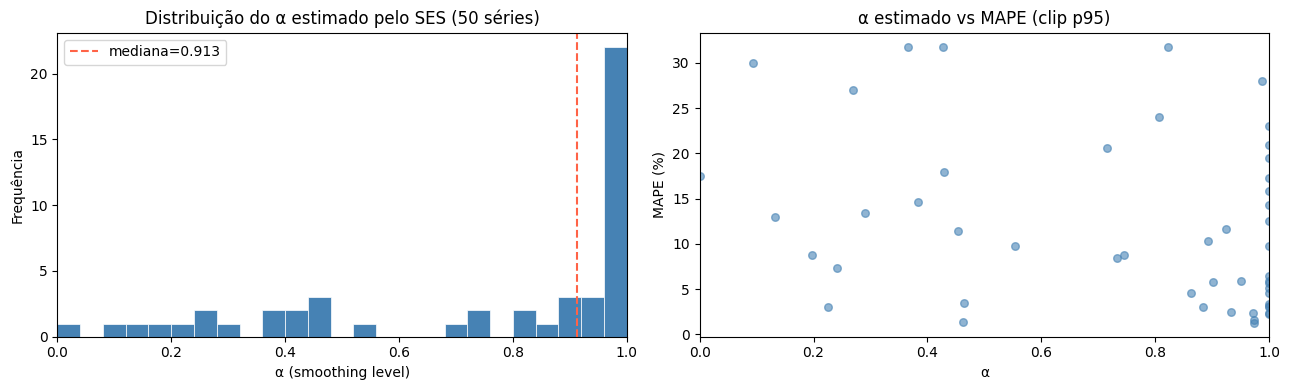

α: min=0.000 | mediana=0.913 | max=1.000


In [8]:
# Coleta o α estimado para cada série (última janela)
alphas = []
for uid in pilot_ids[:50]:   # 50 séries para não demorar
    vals = train_pilot[train_pilot['unique_id']==uid]['y'].values.astype(float)
    if len(vals) < MIN_TRAIN + H:
        continue
    try:
        fit = SimpleExpSmoothing(
            vals, initialization_method='estimated'
        ).fit(optimized=True)
        alphas.append({'unique_id': uid, 'alpha': fit.params['smoothing_level']})
    except Exception:
        pass

alpha_df = pd.DataFrame(alphas)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma de α
axes[0].hist(alpha_df['alpha'], bins=25, color='steelblue',
             edgecolor='white', linewidth=0.5)
axes[0].axvline(alpha_df['alpha'].median(), color='tomato', linestyle='--',
                linewidth=1.5, label=f'mediana={alpha_df["alpha"].median():.3f}')
axes[0].set_title('Distribuição do α estimado pelo SES (50 séries)')
axes[0].set_xlabel('α (smoothing level)')
axes[0].set_ylabel('Frequência')
axes[0].legend()
axes[0].set_xlim(0, 1)

# α vs MAPE
merged = alpha_df.merge(
    by_series_ses[['unique_id','mape']], on='unique_id', how='inner'
)
axes[1].scatter(merged['alpha'], merged['mape'].clip(upper=merged['mape'].quantile(0.95)),
                alpha=0.6, color='steelblue', s=30)
axes[1].set_title('α estimado vs MAPE (clip p95)')
axes[1].set_xlabel('α')
axes[1].set_ylabel('MAPE (%)')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_ses_alpha.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'α: min={alpha_df["alpha"].min():.3f} | '
      f'mediana={alpha_df["alpha"].median():.3f} | '
      f'max={alpha_df["alpha"].max():.3f}')

## 8. Visualização — exemplo de série com SES vs HW vs Persistência

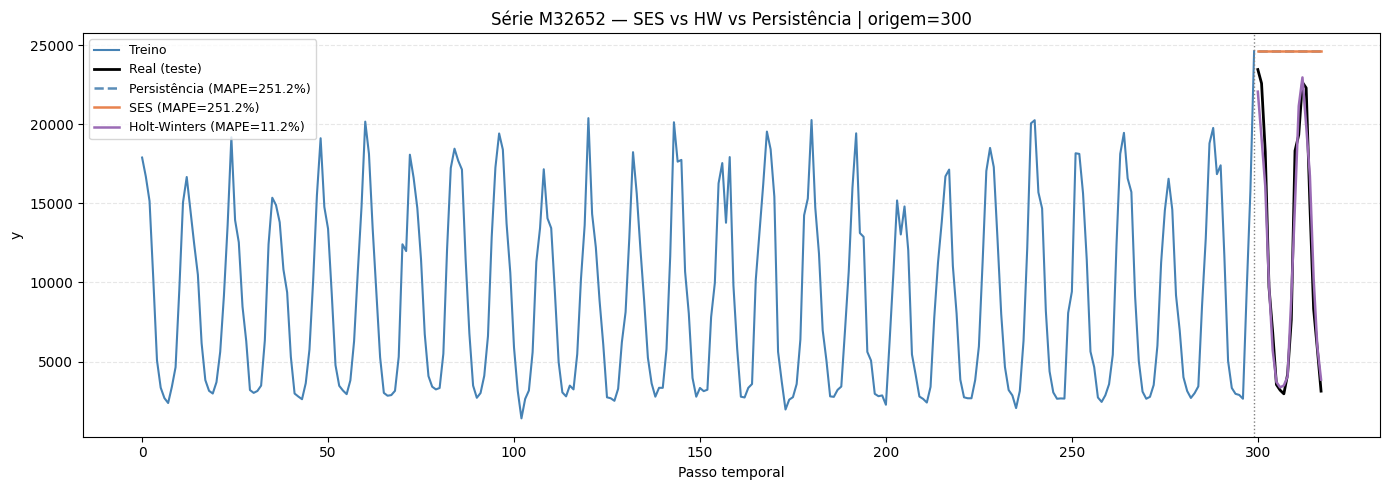

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, horizon, season=12):
    n = len(train)
    if n < 2 * season:
        return np.full(horizon, train[-1])
    best_model, best_aic = None, np.inf
    for stype in (['add'] + (['mul'] if np.all(train > 0) else [])):
        try:
            m = ExponentialSmoothing(
                train, trend='add', seasonal=stype,
                seasonal_periods=season,
                initialization_method='estimated'
            ).fit(optimized=True)
            if m.aic < best_aic:
                best_aic, best_model = m.aic, m
        except Exception:
            continue
    return best_model.forecast(horizon) if best_model else np.full(horizon, train[-1])


# Série com maior diferença SES vs HW
by_series_ses_idx = by_series_ses.set_index('unique_id')
ex_uid = by_series_ses_idx['mape'].idxmax()   # série mais difícil para o SES

ex_vals = train_pilot[train_pilot['unique_id']==ex_uid]['y'].values.astype(float)
ex_wins = make_rolling_windows(ex_vals, H, MIN_TRAIN, N_ORIGINS)
win     = ex_wins[-1]

preds = {
    'Persistência': (np.full(H, win['train'][-1]), '#5B8DB8', '--'),
    'SES'         : (model_ses(win['train'], H),   '#E8834E', '-'),
    'Holt-Winters': (holt_winters(win['train'], H),'#9B6BB5', '-'),
}

fig, ax = plt.subplots(figsize=(14, 5))
x_tr = range(len(win['train']))
x_te = range(len(win['train']), len(win['train'])+H)

ax.plot(x_tr, win['train'], color='steelblue', linewidth=1.5, label='Treino')
ax.plot(x_te, win['test'],  color='black',     linewidth=2,   label='Real (teste)')
ax.axvline(len(win['train'])-1, color='gray', linestyle=':', linewidth=1)

for label, (pred, color, ls) in preds.items():
    mape = calc_mape(win['test'], pred)
    ax.plot(x_te, pred, color=color, linewidth=1.8, linestyle=ls,
            label=f'{label} (MAPE={mape:.1f}%)')

ax.set_title(f'Série {ex_uid} — SES vs HW vs Persistência | origem={win["origin"]}')
ax.set_xlabel('Passo temporal')
ax.set_ylabel('y')
ax.legend(fontsize=9)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / f'fig_ses_exemplo_{ex_uid}.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Salvando artefatos

In [10]:
results_ses.to_csv(RESULT_DIR / 'results_ses_by_window.csv', index=False)
by_series_ses.assign(model='ses').to_csv(
    RESULT_DIR / 'results_ses_by_series.csv', index=False
)

run_log = {
    'timestamp'   : datetime.now().isoformat(),
    'notebook'    : '03_ses',
    'model'       : 'ses',
    'dataset'     : 'M4_Monthly',
    'pilot_n'     : PILOT_N,
    'seed'        : SEED,
    'horizon_H'   : H,
    'min_train'   : MIN_TRAIN,
    'n_origins'   : N_ORIGINS,
    'n_ok'        : int(ok_n),
    'n_errors'    : int(err_n),
    'taxa_sucesso': round(100*ok_n/(ok_n+err_n) if (ok_n+err_n)>0 else 0, 2),
    'mape_median' : round(float(by_series_ses['mape'].median()), 4),
    'mae_median'  : round(float(by_series_ses['mae'].median()),  4),
    'r2_median'   : round(float(by_series_ses['r2'].median()),   4),
    'time_median_s': round(float(by_series_ses['exec_time_s'].median()), 6),
}

with open(RESULT_DIR / 'run_log_ses.json', 'w') as f:
    json.dump(run_log, f, indent=2)

print('Artefatos salvos:')
print('  results_ses_by_window.csv')
print('  results_ses_by_series.csv')
print('  run_log_ses.json')
print()
print(json.dumps(run_log, indent=2))

Artefatos salvos:
  results_ses_by_window.csv
  results_ses_by_series.csv
  run_log_ses.json

{
  "timestamp": "2026-05-22T15:16:51.050585",
  "notebook": "03_ses",
  "model": "ses",
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "min_train": 24,
  "n_origins": 3,
  "n_ok": 600,
  "n_errors": 0,
  "taxa_sucesso": 100.0,
  "mape_median": 8.7764,
  "mae_median": 253.5196,
  "r2_median": -1.1898,
  "time_median_s": 0.003779
}


## 10. Resumo interpretativo

---

### O que esperar do SES no M4 mensal

O M4 mensal é composto majoritariamente por séries com **tendência e/ou sazonalidade** — exatamente as características que o SES **não modela**. Por isso, espera-se que o SES fique próximo ou abaixo do Holt-Winters, mas potencialmente melhor que a persistência em séries estacionárias.

### Interpretação do α estimado
- **α alto (> 0.5)**: série com mudanças rápidas — modelo descarta histórico distante
- **α baixo (< 0.2)**: série estável — modelo pondera longo histórico
- **α próximo de 1**: equivale quase à persistência (último valor domina)

Essa distribuição de α é um resultado interpretativo relevante para a seção de explicabilidade da dissertação — mostra heterogeneidade das séries do M4.

---

### Próximo notebook: `04_sarima.ipynb`
- SARIMA com seleção automática de ordem por AIC
- Tratamento de falhas de convergência
- Comparação acumulada com 6 modelos